# **AIMLCZG523 Machine Learning Operations (MLOps) - Assignment 1**

<table>
  <tr>
    <td><b>Name:</b></td>
    <td>Harshavardan M</td>
  </tr>
  <tr>
    <td><b>BITS ID:</b></td>
    <td>2025ct05070@wilp.bits-pilani.ac.in</td>
  </tr>
  <tr>
    <td><b>Date:</b></td>
    <td>19/10/2026</td>
  </tr>
</table>

# Heart Disease Prediction — Exploratory Data Analysis

## Objective

Explore the UCI Heart Disease dataset to understand its structure, missing values, feature distributions and target balance before developing a reproducible classification pipeline.

## Dataset selection

The project initially uses the Cleveland source dataset as the primary modelling dataset because it contains 303 records, 13 input features and only 6 missing cells. The Hungarian, Switzerland and VA Long Beach datasets will be evaluated separately for potential inclusion in a combined-data experiment.

## Target definition

The original `num` target contains values from 0 to 4. For binary classification, the proposed target is:

* `0`: no heart disease (`num = 0`)
* `1`: heart disease present (`num > 0`)


In [2]:
#Loading the data

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd()

# locating the project root using the expected data file.

if not (PROJECT_ROOT / "data" / "raw" / "processed.cleveland.data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DIR = PROJECT_ROOT / "data" / "raw"

COLUMNS = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "num"
]

DATASETS = {
    "Cleveland": "processed.cleveland.data",
    "Hungarian": "processed.hungarian.data",
    "Switzerland": "processed.switzerland.data",
    "VA Long Beach": "processed.va.data",
}

def load_dataset(filename):
    df = pd.read_csv(
        RAW_DIR / filename,
        header=None,
        names=COLUMNS,
        na_values=["?"],
        skipinitialspace=True,
    )

    for col in COLUMNS:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df["target"] = np.where(df["num"].isna(), np.nan,
                            (df["num"] > 0).astype(int))
    return df

datasets = {
    name: load_dataset(filename)
    for name, filename in DATASETS.items()
}

cleveland = datasets["Cleveland"]

print("Project root:", PROJECT_ROOT)
print("Cleveland shape:", cleveland.shape)
display(cleveland.head())
display(cleveland.describe().T)

Project root: c:\Users\Himaanish\Documents\heart-disease-mlops
Cleveland shape: (303, 15)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,0.0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2,1.0
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,1.0
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,0.0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,0.0


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


In [4]:
#Comparing the datasets

summary = []

for name, df in datasets.items():
    summary.append({
        "dataset": name,
        "records": len(df),
        "features_including_original_target": 14,
        "missing_cells": int(df[COLUMNS].isna().sum().sum()),
        "records_with_missing_values": int(
            df[COLUMNS].isna().any(axis=1).sum()
        ),
        "negative_cases": int((df["target"] == 0).sum()),
        "positive_cases": int((df["target"] == 1).sum()),
        "duplicate_rows": int(df[COLUMNS].duplicated().sum()),
    })

summary_df = pd.DataFrame(summary)
display(summary_df)

,dataset,records,features_including_original_target,missing_cells,records_with_missing_values,negative_cases,positive_cases,duplicate_rows
0,Cleveland,303,14,6,6,164,139,0
1,Hungarian,294,14,782,293,188,106,1
2,Switzerland,123,14,273,123,8,115,0
3,VA Long Beach,200,14,698,199,51,149,1


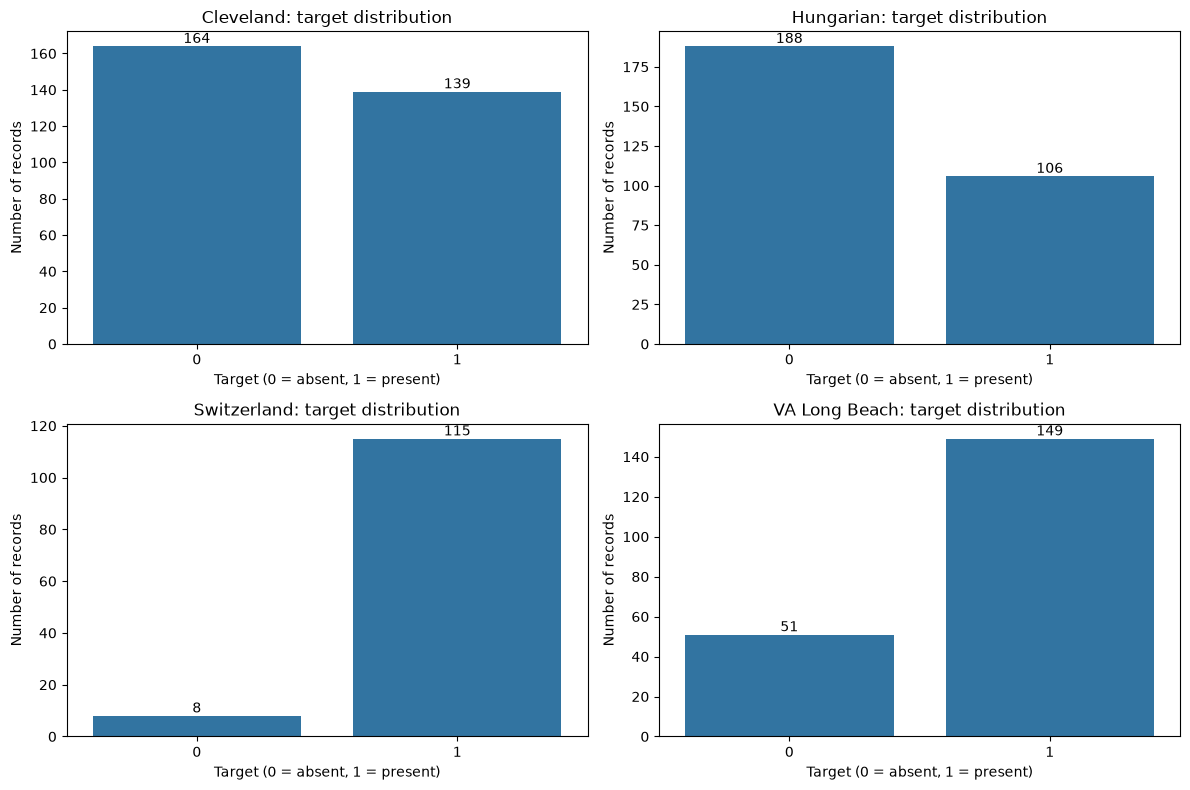

In [5]:
#Visualizing target balance

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for ax, (name, df) in zip(axes, datasets.items()):
    counts = df["target"].value_counts().reindex(
        [0, 1], fill_value=0
    )

    sns.barplot(
        x=counts.index.astype(str),
        y=counts.values,
        ax=ax,
    )

    ax.set_title(f"{name}: target distribution")
    ax.set_xlabel("Target (0 = absent, 1 = present)")
    ax.set_ylabel("Number of records")

    for container in ax.containers:
        ax.bar_label(container)

plt.tight_layout()
plt.show()

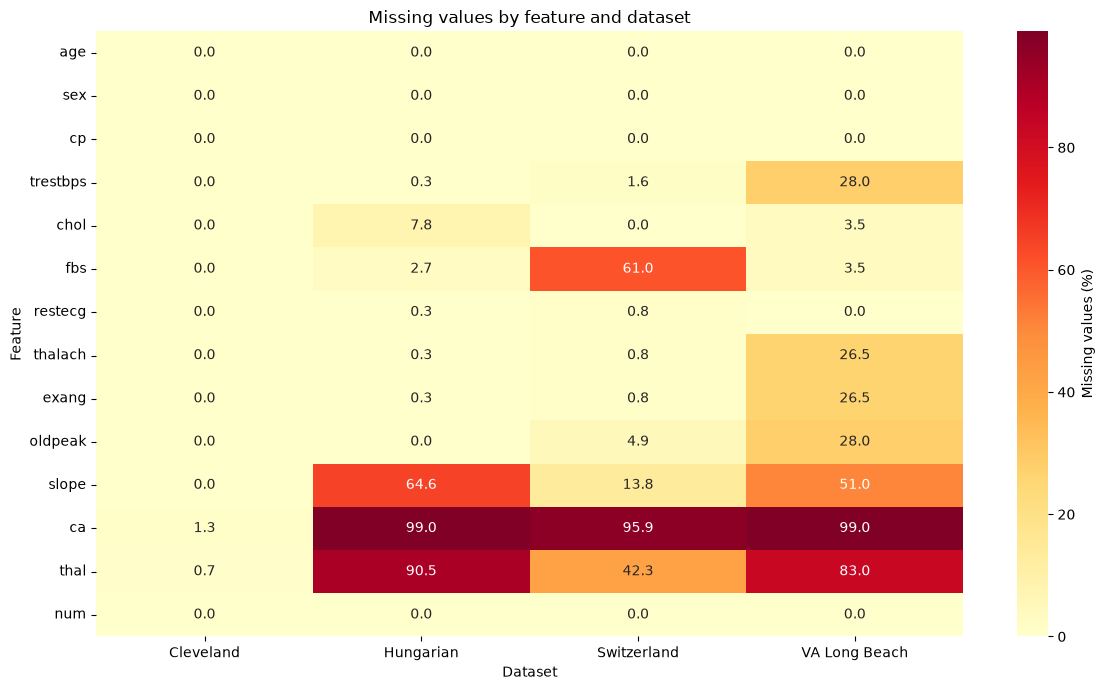

In [6]:
#Visualizing missing values

missing_pct = pd.DataFrame({
    name: df[COLUMNS].isna().mean() * 100
    for name, df in datasets.items()
})

plt.figure(figsize=(12, 7))
sns.heatmap(
    missing_pct,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    cbar_kws={"label": "Missing values (%)"},
)
plt.title("Missing values by feature and dataset")
plt.xlabel("Dataset")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

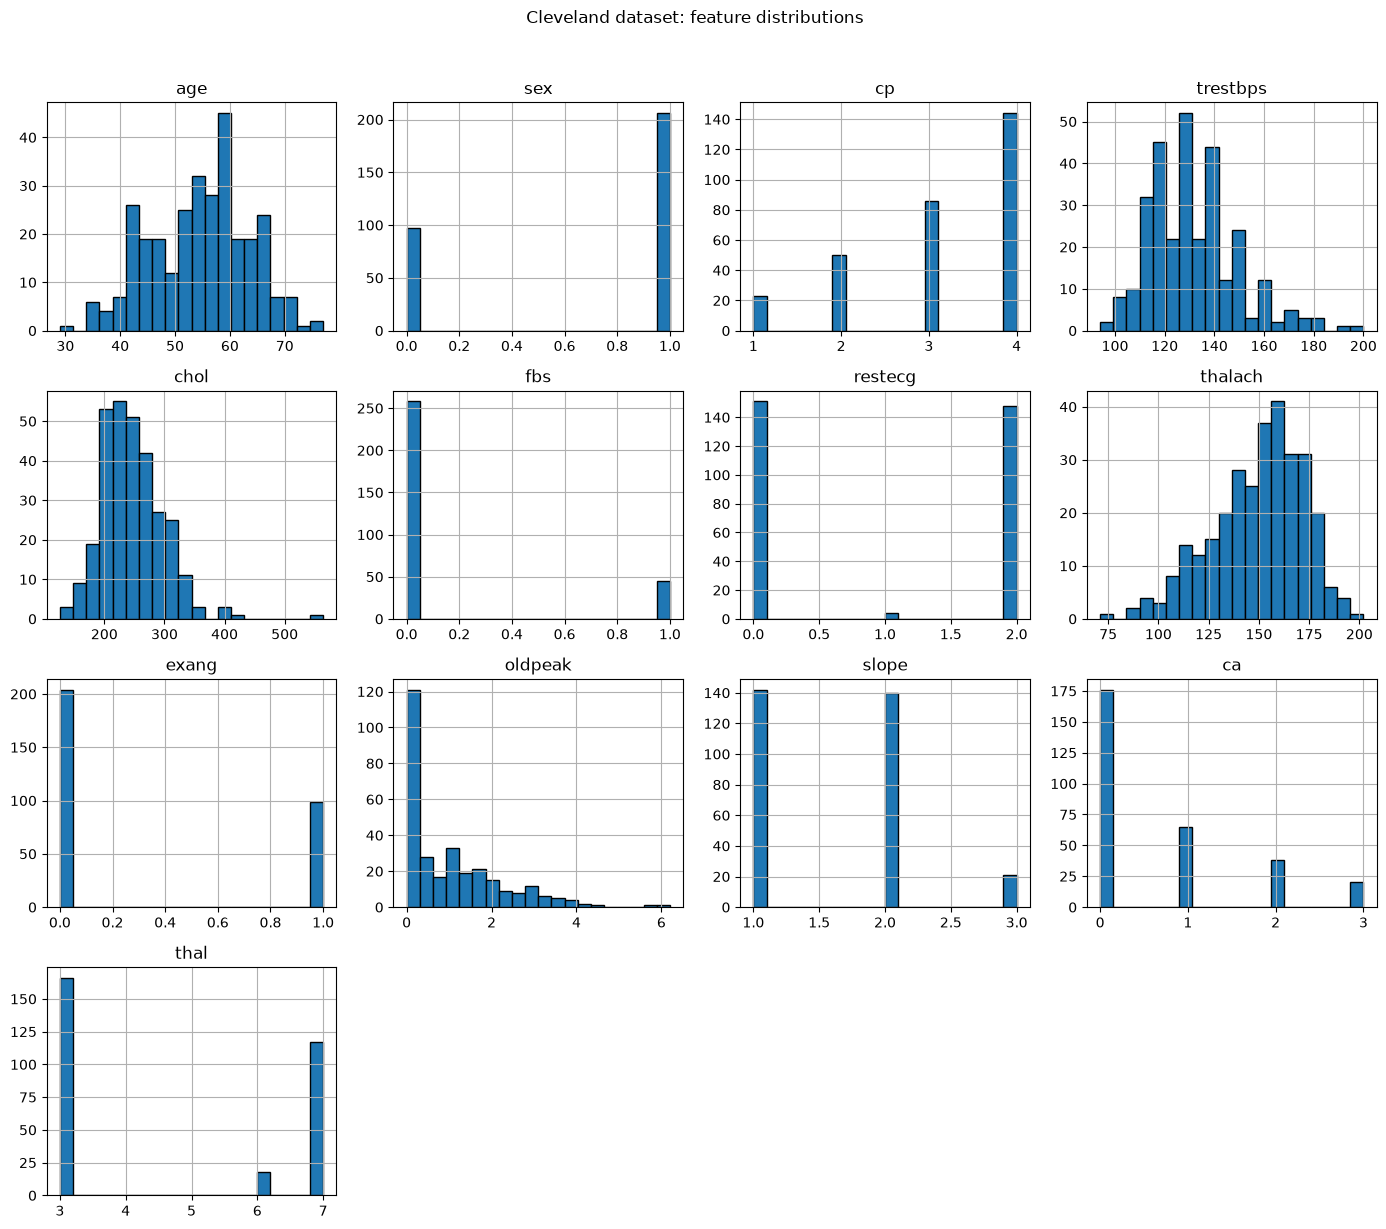

In [7]:
#Plotting Cleveland feature distributions

cleveland_features = cleveland[COLUMNS].drop(
    columns=["num"]
)

cleveland_features.hist(
    bins=20,
    figsize=(14, 12),
    edgecolor="black",
)
plt.suptitle(
    "Cleveland dataset: feature distributions",
    y=1.02,
)
plt.tight_layout()
plt.show()

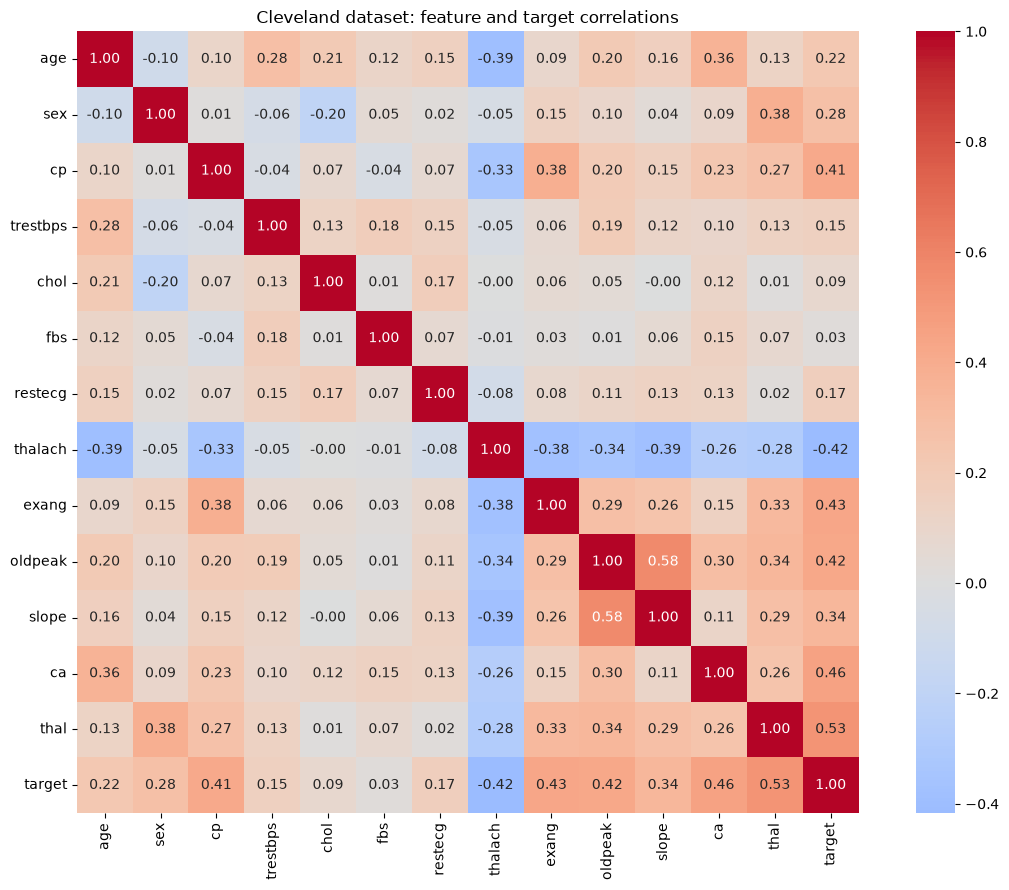

In [9]:
#Correlation heatmap

plt.figure(figsize=(12, 9))

correlation_columns = [
    col for col in COLUMNS if col != "num"
] + ["target"]

correlation = cleveland[correlation_columns].corr()

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
)

plt.title("Cleveland dataset: feature and target correlations")
plt.tight_layout()
plt.show()

## EDA Findings and Implications for Modelling

### Dataset selection

The Cleveland dataset contains 303 records and 13 input features. Only six values are missing, making it a practical starting point for the initial classification experiments. The other three source datasets contain substantially more missing values and will not be combined with Cleveland until their compatibility and data quality have been evaluated.

### Target distribution

The Cleveland dataset contains 164 records without heart disease and 139 records with heart disease. The classes are reasonably balanced, although the positive and negative classes are not exactly equal. We will therefore evaluate precision, recall and ROC-AUC alongside accuracy during model development.

### Missing values and duplicates

The Cleveland dataset has missing values in the `ca` and `thal` features. These must be handled using a preprocessing method fitted on the training data to avoid data leakage. The Hungarian and VA Long Beach datasets also contain duplicate rows, which should be investigated before any combined-data experiment.

### Feature distributions and correlations

The histograms show the distributions of the Cleveland input features, while the correlation heatmap provides an initial view of linear relationships between numerical representations of the features and the binary target. Integer-coded categorical features require cautious interpretation because their numeric codes do not necessarily represent equal intervals.

### Next steps

The modelling stage will use a reproducible preprocessing pipeline for missing-value imputation and categorical-feature handling where appropriate. At least two classification models will then be evaluated using cross-validation and suitable classification metrics.